In [6]:
%reload_ext autoreload
%autoreload 2

import numpy as np, pretty_midi, mir_eval
from pianotrans.pipeline import transcribe
from pathlib import Path
from collections import Counter

def check(name, verbose=True):
    path = f"../data/test/{name}"
    ref = pretty_midi.PrettyMIDI(path + ".mid").instruments[0].notes
    est = transcribe(path + ".wav")
    ri = np.array([[n.start, n.end] for n in ref]); rp = np.array([pretty_midi.note_number_to_hz(n.pitch) for n in ref])
    ei = np.array([[n.onset, n.offset] for n in est]).reshape(-1, 2); ep = np.array([pretty_midi.note_number_to_hz(n.pitch) for n in est])

    on_only = dict(mir_eval.transcription.match_notes(ri, rp, ei, ep, offset_ratio=None))
    full_ref = {i for i, _ in mir_eval.transcription.match_notes(ri, rp, ei, ep)}
    matched_est = set(on_only.values())
    nm = pretty_midi.note_number_to_name
    counts = Counter()

    lines = []
    for i, n in enumerate(ref):
        if i not in on_only:
            counts["missed"] += 1; lines.append(f"  MISSED   {nm(n.pitch):4s} {n.start:6.2f}-{n.end:6.2f}")
        elif i not in full_ref:
            counts["offset"] += 1
            last = " (last note)" if i == len(ref) - 1 else ""
            lines.append(f"  OFFSET   {nm(n.pitch):4s} true end {n.end:6.2f}  detected {est[on_only[i]].offset:6.2f}{last}")
    for j, n in enumerate(est):
        if j not in matched_est:
            counts["extra"] += 1; lines.append(f"  EXTRA    {nm(n.pitch):4s} {n.onset:6.2f}-{n.offset:6.2f}")

    if verbose and lines:
        print(f"--- {name}: {len(ref)} true, {len(est)} detected"); print("\n".join(lines))
    return counts

total = Counter()
for wav in sorted(Path("../data/test").glob("*.wav")):
    total += check(wav.stem)
print("\nTOTAL:", dict(total))

--- melody_001: 16 true, 16 detected
  OFFSET   A4   true end   9.47  detected  10.47 (last note)
--- melody_002: 16 true, 17 detected
  OFFSET   D5   true end  12.88  detected  13.82 (last note)
  EXTRA    D5    10.21- 11.24
--- melody_004: 16 true, 17 detected
  MISSED   G#4    2.88-  3.31
  EXTRA    G4     2.90-  3.00
  EXTRA    G#4    3.00-  3.33
--- melody_006: 16 true, 16 detected
  OFFSET   G#3  true end  11.55  detected  12.39 (last note)
--- melody_007: 16 true, 17 detected
  OFFSET   E4   true end  10.50  detected  10.65 (last note)
  EXTRA    B4     4.69-  5.13
--- melody_008: 16 true, 16 detected
  OFFSET   E4   true end   1.83  detected   1.88
  OFFSET   B3   true end  10.74  detected  11.75 (last note)
--- melody_010: 16 true, 16 detected
  MISSED   G4     9.54- 10.62
  OFFSET   A4   true end  12.43  detected  13.41 (last note)
  EXTRA    G4     9.60- 10.75
--- melody_011: 16 true, 16 detected
  OFFSET   G#3  true end  10.01  detected  10.07 (last note)
--- melody_012: 16

steepest fall WHILE HELD : median 0.9  95% 2.7  max 6.1 dB/46ms
steepest fall AT RELEASE : median 4.1  min 2.4 dB/46ms


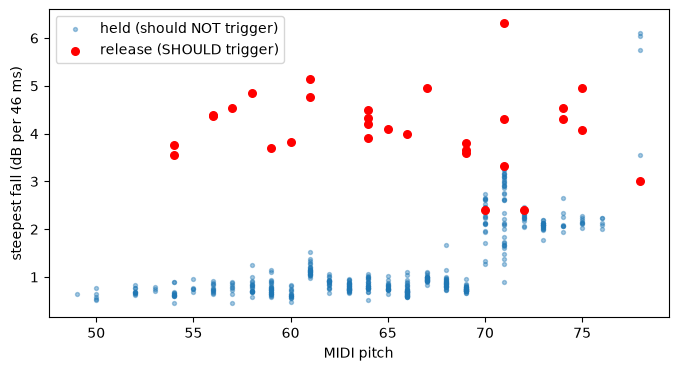

In [11]:
import librosa
from pianotrans.load import load_audio
from pianotrans.config import HOP

W = 4   # 4 frames ~ 46 ms
held, rel, rel_pitch, held_pitch = [], [], [], []
for wav in sorted(Path("../data/test").glob("*.wav")):
    y, sr = load_audio(str(wav))
    db = librosa.amplitude_to_db(librosa.feature.rms(y=y, hop_length=HOP)[0], ref=np.max)
    slope = np.r_[db[:-W] - db[W:], np.zeros(W)]          # dB lost over the next 46 ms
    notes = pretty_midi.PrettyMIDI(str(wav.with_suffix(".mid"))).instruments[0].notes
    for i, n in enumerate(notes):
        s, e = librosa.time_to_frames([n.start, n.end], sr=sr, hop_length=HOP)
        if e - W - (s + 9) > 0:
            held.append(slope[s + 9:e - W].max()); held_pitch.append(n.pitch)
        if i == len(notes) - 1:                           # last note: release is clean
            rel.append(slope[e - 2:e + 6].max()); rel_pitch.append(n.pitch)

held, rel = np.array(held), np.array(rel)
print(f"steepest fall WHILE HELD : median {np.median(held):.1f}  95% {np.percentile(held, 95):.1f}  max {held.max():.1f} dB/46ms")
print(f"steepest fall AT RELEASE : median {np.median(rel):.1f}  min {rel.min():.1f} dB/46ms")

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(held_pitch, held, s=8, alpha=0.4, label="held (should NOT trigger)")
ax.scatter(rel_pitch, rel, s=30, color="red", label="release (SHOULD trigger)")
ax.set_xlabel("MIDI pitch"); ax.set_ylabel("steepest fall (dB per 46 ms)"); ax.legend()
fig.savefig("../figures/release_slope_vs_pitch.png", dpi=150, bbox_inches="tight")

In [12]:
import io, contextlib, sys
sys.path.insert(0, "../eval")
import evaluate
import pianotrans.segment as seg

original = seg.find_release
for slope in [3, 4, 5]:
    for r in [2, 3]:
        seg.find_release = lambda s, e, db, slope_db=None, **k: original(s, e, db, slope_db=slope, ratio=r)
        with contextlib.redirect_stdout(io.StringIO()):
            n, scores = evaluate.evaluate()
        print(f"slope_db={slope} ratio={r}: F1={scores['f1']:.3f}  onset-only={scores['f1_no_offset']:.3f}")
seg.find_release = original

slope_db=3 ratio=2: F1=0.937  onset-only=0.974
slope_db=3 ratio=3: F1=0.899  onset-only=0.974
slope_db=4 ratio=2: F1=0.910  onset-only=0.974
slope_db=4 ratio=3: F1=0.897  onset-only=0.974
slope_db=5 ratio=2: F1=0.897  onset-only=0.974
slope_db=5 ratio=3: F1=0.897  onset-only=0.974


In [23]:
import time
from pianotrans.pitch import track_f0, f0_to_activation
from pianotrans.tuning import estimate_tuning
from pianotrans.onsets import onset_envelope, detect_onsets
from pianotrans.pipeline import loudness_db
import pianotrans.segment as seg

# 1. Run the slow stages ONCE per file and keep the results
t0 = time.time()
cache = []
for wav in sorted(Path("../data/test").glob("*.wav")):
    y, sr = load_audio(str(wav))
    f0, voiced, _ = track_f0(y, sr)
    A = f0_to_activation(f0, voiced, estimate_tuning(f0, voiced))
    onset_frames = detect_onsets(onset_envelope(y, sr), sr)
    ref = pretty_midi.PrettyMIDI(str(wav.with_suffix(".mid"))).instruments[0].notes
    ri = np.array([[n.start, n.end] for n in ref])
    rp = np.array([pretty_midi.note_number_to_hz(n.pitch) for n in ref])
    cache.append((A, onset_frames, loudness_db(y), sr, ri, rp))
print(f"cached {len(cache)} files in {time.time() - t0:.0f} s")

cached 30 files in 253 s


In [26]:
print(score(slope_db=100, ratio=100))   # thresholds impossible to reach = release detection off
print(score(slope_db=3, ratio=1.5))     # your chosen setting

(np.float64(0.9013776453885564), np.float64(0.9751525556459144))
(np.float64(0.9605020180115056), np.float64(0.9751525556459144))


In [27]:
# 2. Rerun only segmentation (fast) for each setting
def score(slope_db, ratio):
    original = seg.find_release
    seg.find_release = lambda s, e, db, *args, **kw: original(s, e, db, slope_db=slope_db, ratio=ratio)
    f1s, f1on = [], []
    for A, onset_frames, rms_db, sr, ri, rp in cache:
        est = seg.activation_to_notes(A, onset_frames, sr, rms_db=rms_db)
        ei = np.array([[n.onset, n.offset] for n in est]).reshape(-1, 2)
        ep = np.array([pretty_midi.note_number_to_hz(n.pitch) for n in est])
        f1s.append(mir_eval.transcription.precision_recall_f1_overlap(ri, rp, ei, ep)[2])
        f1on.append(mir_eval.transcription.precision_recall_f1_overlap(ri, rp, ei, ep, offset_ratio=None)[2])
    seg.find_release = original
    return np.mean(f1s), np.mean(f1on)

for slope in [2, 2.5, 3, 3.5, 4]:
    for r in [1.5, 2, 3]:
        f1, on = score(slope, r)
        print(f"slope_db={slope:<4} ratio={r:<4} F1={f1:.3f}  onset-only={on:.3f}")

slope_db=2    ratio=1.5  F1=0.938  onset-only=0.975
slope_db=2    ratio=2    F1=0.953  onset-only=0.975
slope_db=2    ratio=3    F1=0.914  onset-only=0.975
slope_db=2.5  ratio=1.5  F1=0.950  onset-only=0.975
slope_db=2.5  ratio=2    F1=0.953  onset-only=0.975
slope_db=2.5  ratio=3    F1=0.901  onset-only=0.975
slope_db=3    ratio=1.5  F1=0.961  onset-only=0.975
slope_db=3    ratio=2    F1=0.949  onset-only=0.975
slope_db=3    ratio=3    F1=0.901  onset-only=0.975
slope_db=3.5  ratio=1.5  F1=0.958  onset-only=0.975
slope_db=3.5  ratio=2    F1=0.936  onset-only=0.975
slope_db=3.5  ratio=3    F1=0.901  onset-only=0.975
slope_db=4    ratio=1.5  F1=0.946  onset-only=0.975
slope_db=4    ratio=2    F1=0.920  onset-only=0.975
slope_db=4    ratio=3    F1=0.901  onset-only=0.975
